# Lab Day 10 (Kaggle) — Finetune Qwen3-VL-4B + LoRA cho grounding hư hại mặt đường
Đặng Đỉnh Đoàn · 2A202602927. Notebook này chạy **một lần Save & Run All**: E0 → E1/E2/E3 → E4 (→ E5 nếu bật) → phân tích → báo cáo.

**Trước khi bấm *Save Version → Save & Run All (Commit)*:**
1. *Settings → Accelerator*: **GPU T4 ×2** (không chọn P100). *Internet*: **On**.
2. *Add Input → Datasets*: tìm `road-damage-dataset-potholes-cracks-and-manholes` (tác giả `lorenzoarcioni`) rồi Add.
3. (Tuỳ chọn) *Add-ons → Secrets*: thêm `HF_TOKEN` để tải model nhanh hơn.
4. Mã nguồn đã nhúng sẵn trong cell kế tiếp, **không cần upload ZIP**.

Hai GPU chạy hai lane song song (lane 0: E1 → E3; lane 1: E0 → E2), sau đó E4. Ước tính thô 4–7 giờ (chưa đo trên Kaggle), nằm trong giới hạn 12 giờ của một phiên chạy.
Mỗi lane ghi log vào `work/logs/`; một lane lỗi không làm hỏng lane kia. Cuối notebook có bảng tổng kết và file `day10_results.zip`.

**Chạy lại sau khi có thí nghiệm lỗi:** *Add Input → Notebooks → Your Work* rồi chọn chính notebook này (output của lần chạy trước).
Cell "Dùng lại kết quả" sẽ khôi phục E0–E3 đã hoàn chỉnh; chỉ phần thiếu/lỗi được chạy lại.

In [1]:
# Mã nguồn bài lab (solution/, scripts/, configs/, tests/) nhúng dạng ZIP+base64.
# Sinh bởi `python -m solution.make_kaggle_notebook`; sửa code xong phải sinh lại notebook.
CODE_ZIP_B64 = """
...
"""

## 0. Môi trường
Giải nén mã nguồn, đặt công tắc, kiểm tra GPU, cài thư viện. Mọi lệnh nặng chạy bằng tiến trình con với `PYTHONUNBUFFERED=1` nên log hiện ngay.

In [2]:
import base64, io, json, os, re, shutil, subprocess, sys, threading, time, zipfile
from collections import deque
from pathlib import Path

# ---------------- Công tắc ----------------
RUN_E5 = False            # GRPO bonus: bật riêng sau khi E0–E4 ổn định.
USE_ALL_GPUS = True       # T4 x2 -> hai lane song song; chỉ có 1 GPU thì tự chạy tuần tự.
BATCH_SIZE, GRAD_ACCUM = 2, 4   # đúng configs/e1–e3 (effective batch 8); đừng đổi giữa các setup.
INFER_BS = 8              # batch suy luận: chỉ ảnh hưởng tốc độ, không ảnh hưởng nhãn/split.
KEEP_ADAPTERS = True      # giữ adapter + projector cuối; luôn xoá optimizer state để output gọn.
CLEAN_DATA_IMAGES = True  # xoá bản sao ảnh data/images ở cuối (giữ splits/*.jsonl).

T_START = time.time()
IN_KAGGLE = Path('/kaggle/working').exists()
REPO_DIR = Path('/kaggle/working/day10') if IN_KAGGLE else Path.cwd() / 'day10_kaggle_run'
REPO_DIR.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(io.BytesIO(base64.b64decode(CODE_ZIP_B64))) as zf:
    zf.extractall(REPO_DIR)
os.chdir(REPO_DIR)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

os.environ.update(PYTHONUNBUFFERED='1',          # print() của tiến trình con hiện ngay, không bị đệm
                  TOKENIZERS_PARALLELISM='false',
                  HF_HUB_DISABLE_PROGRESS_BARS='1',
                  PIP_DISABLE_PIP_VERSION_CHECK='1')


def kaggle_secret(name):
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(name)
    except Exception:
        return None


if not os.environ.get('HF_TOKEN'):
    token = kaggle_secret('HF_TOKEN')
    if token:
        os.environ['HF_TOKEN'] = token
print('Repo:', REPO_DIR, '| Kaggle:', IN_KAGGLE, '| Python', sys.version.split()[0],
      '| HF_TOKEN:', 'có' if os.environ.get('HF_TOKEN') else 'không')

Repo: /kaggle/working/day10 | Kaggle: True | Python 3.13.15 | HF_TOKEN: không


In [3]:
# ---------------- Helper: chạy lệnh có stream log + lane GPU song song ----------------
SEEN_WARN = set()


def _clean(line):
    s = line.rstrip()
    if not s or 'Loading weights' in s:
        return None
    if re.search(r'\d+%\|', s) and '100%' not in s:      # chỉ giữ thanh tiến trình tqdm lúc xong
        return None
    if s.startswith('[transformers]') or 'warn' in s.lower():
        if s in SEEN_WARN:                                 # cảnh báo lặp mỗi batch chỉ in một lần
            return None
        SEEN_WARN.add(s)
    return s


def PY(*args):
    return [sys.executable] + [str(a) for a in args]


def run_stream(argv, soft=False, tail=60):
    # Chạy một lệnh, in log theo thời gian thực. soft=True: lỗi chỉ cảnh báo, không dừng notebook.
    argv = [str(a) for a in argv]
    shown = ' '.join(argv)
    print('$', shown if len(shown) < 300 else shown[:300] + ' ...', flush=True)
    t0 = time.time()
    proc = subprocess.Popen(argv, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                            bufsize=1, errors='replace', env=os.environ.copy())
    last = deque(maxlen=tail)
    for line in proc.stdout:
        s = _clean(line)
        if s is not None:
            print(s, flush=True)
            last.append(s)
    rc = proc.wait()
    print(f'-> exit {rc} ({(time.time() - t0) / 60:.1f} phút)', flush=True)
    if rc != 0 and not soft:
        raise RuntimeError(f'Lệnh lỗi (exit {rc}): ' + ' '.join(argv)
                           + f'\n--- {len(last)} dòng cuối ---\n' + '\n'.join(last))
    return rc == 0


class Lane(threading.Thread):
    # Một lane = một GPU, chạy lần lượt các nhóm lệnh (mỗi nhóm = một thí nghiệm).
    # Lệnh lỗi chỉ dừng nhóm đó; nhóm kế tiếp vẫn chạy. Chỉ luồng chính được print.
    def __init__(self, name, gpu, groups):
        super().__init__(daemon=True)
        self.lane, self.gpu, self.groups = name, gpu, groups
        self.log_path = Path('work/logs') / f'{name}.log'
        self.log_path.parent.mkdir(parents=True, exist_ok=True)
        self.log_path.write_bytes(b'')
        self.status, self.pos = {}, 0

    def run(self):
        env = os.environ.copy()
        if self.gpu is not None:
            env['CUDA_VISIBLE_DEVICES'] = str(self.gpu)
        with self.log_path.open('ab', buffering=0) as log:
            for title, steps in self.groups:
                t0 = time.time()
                log.write(f'\n===== {title} =====\n'.encode())
                try:
                    for step in steps:
                        if callable(step):
                            step()
                            continue
                        log.write(('$ ' + ' '.join(step) + '\n').encode())
                        rc = subprocess.call(step, stdout=log, stderr=subprocess.STDOUT, env=env)
                        if rc != 0:
                            raise RuntimeError(f'exit {rc}: ' + ' '.join(step[2:6]))
                    self.status[title] = f'ok ({(time.time() - t0) / 60:.0f} phút)'
                except Exception as exc:
                    self.status[title] = f'LỖI: {exc}'
                    log.write(f'!! {title} LỖI: {exc}\n'.encode())

    def drain(self, final=False):
        if not self.log_path.exists():
            return
        with self.log_path.open('rb') as f:
            f.seek(self.pos)
            data = f.read()
        if not final:
            cut = max(data.rfind(b'\n'), data.rfind(b'\r'))
            if cut < 0:
                return
            data = data[:cut + 1]
        self.pos += len(data)
        for line in data.decode('utf-8', 'replace').replace('\r', '\n').split('\n'):
            s = _clean(line)
            if s is not None:
                print(f'[{self.lane}] {s}', flush=True)


def run_lanes(lanes, poll=20, heartbeat=600):
    t0, last_beat = time.time(), time.time()
    for lane in lanes:
        lane.start()
    while any(lane.is_alive() for lane in lanes):
        time.sleep(poll)
        for lane in lanes:
            lane.drain()
        if time.time() - last_beat > heartbeat:
            last_beat = time.time()
            print(f'... đang chạy {(time.time() - t0) / 60:.0f} phút (tổng {(time.time() - T_START) / 3600:.2f} giờ)', flush=True)
    for lane in lanes:
        lane.join()
        lane.drain(final=True)
    print('\n== Kết quả lane ==')
    failed = []
    for lane in lanes:
        for title, status in lane.status.items():
            print(f'  [{lane.lane}/GPU{lane.gpu}] {title}: {status}')
            if status.startswith('LỖI'):
                failed.append(title)
    print(f'Phase xong sau {(time.time() - t0) / 60:.1f} phút; tổng {(time.time() - T_START) / 3600:.2f} giờ')
    return failed


def predict_step(name, split, pred, score_out, checkpoint=None, config=None):
    cmd = PY('-m', 'solution.run', 'predict', '--allow-gpu')
    cmd += ['--config', config] if config else ['--checkpoint', checkpoint]
    cmd += ['--pred', pred, '--split', split, '--batch-size', INFER_BS, '--resume',
            '--score-out', score_out, '--name', name]
    return [str(c) for c in cmd]


def train_step(config, out):
    # Trả None nếu đã train xong; tự resume từ checkpoint cuối nếu lần trước bị ngắt giữa chừng.
    out = Path(out)
    cmd = PY('-m', 'solution.run', 'train', '--allow-gpu', '--config', config, '--out', out,
             '--batch-size', BATCH_SIZE, '--grad-accum', GRAD_ACCUM)
    if (out / 'run.json').exists() and json.loads((out / 'run.json').read_text()).get('finished'):
        return None
    if (out / 'latest.json').exists():
        last = out / json.loads((out / 'latest.json').read_text())['checkpoint']
        if last.is_dir():
            return cmd + ['--resume', str(last)]
    if out.exists():
        shutil.rmtree(out)          # lần trước hỏng trước checkpoint đầu tiên: bắt đầu lại sạch
    return cmd


def prune_checkpoints(run_dir):
    # Sau khi train xong chỉ giữ checkpoint cuối (disk /kaggle/working giới hạn 20GB).
    run_dir = Path(run_dir)
    if not ((run_dir / 'latest.json').exists() and (run_dir / 'run.json').exists()):
        return
    if not json.loads((run_dir / 'run.json').read_text()).get('finished'):
        return
    keep = json.loads((run_dir / 'latest.json').read_text())['checkpoint']
    for path in run_dir.glob('checkpoint-*'):
        if path.is_dir() and path.name != keep:
            shutil.rmtree(path, ignore_errors=True)


def sft_group(exp):
    cfg, out = f'configs/{exp}.yaml', f'work/{exp}'
    steps = []
    train = train_step(cfg, out)
    if train:
        steps.append(train)
    steps.append(lambda out=out: prune_checkpoints(out))
    steps.append(predict_step(exp.upper(), 'val', f'work/{exp}_val.jsonl', f'work/{exp}_val_score.json', checkpoint=out))
    steps.append(predict_step(exp.upper(), 'test', f'work/{exp}.jsonl', f'report/evidence/{exp}.json', checkpoint=out))
    return (exp.upper(), steps)


def make_lanes(groups_by_gpu):
    # groups_by_gpu: danh sách các danh sách nhóm; thiếu GPU thì gộp tất cả vào một lane tuần tự.
    if N_GPU >= len(groups_by_gpu):
        return [Lane(f'gpu{i}', i, groups) for i, groups in enumerate(groups_by_gpu) if groups]
    merged = sorted((g for groups in groups_by_gpu for g in groups), key=lambda g: g[0])
    return [Lane('gpu0', 0, merged)]

In [4]:
# ---------------- Kiểm tra GPU, disk ----------------
query = 'name,memory.total,compute_cap'
smi = subprocess.run(['nvidia-smi', f'--query-gpu={query}', '--format=csv,noheader'], capture_output=True, text=True)
if smi.returncode != 0:
    smi = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                         capture_output=True, text=True)
gpu_rows = [r.strip() for r in smi.stdout.splitlines() if r.strip()] if smi.returncode == 0 else []
if not gpu_rows:
    raise RuntimeError('Không thấy GPU. Settings -> Accelerator -> GPU T4 x2, rồi Run All lại.')
for i, row in enumerate(gpu_rows):
    print(f'GPU {i}: {row}')
if any('P100' in r for r in gpu_rows):
    print('CẢNH BÁO: P100 không phù hợp (bitsandbytes 4-bit/tốc độ). Nên chọn GPU T4 x2.')
N_GPU = len(gpu_rows) if USE_ALL_GPUS else 1
print('Số lane GPU sẽ dùng:', N_GPU)
for p in ('/kaggle/working', '/tmp'):
    if Path(p).exists():
        usage = shutil.disk_usage(p)
        print(f'Disk {p}: trống {usage.free / 1e9:.1f} GB / {usage.total / 1e9:.1f} GB')

GPU 0: Tesla T4, 15360 MiB, 7.5
GPU 1: Tesla T4, 15360 MiB, 7.5
Số lane GPU sẽ dùng: 2
Disk /kaggle/working: trống 20.9 GB / 21.0 GB
Disk /tmp: trống 1148.8 GB / 8758.4 GB


In [5]:
# ---------------- Cài thư viện (giữ torch/torchvision có sẵn của Kaggle) ----------------
SKIP = {'kaggle', 'nbformat'}                      # dữ liệu lấy từ /kaggle/input, không cần
if not RUN_E5:
    SKIP |= {'trl', 'datasets'}
reqs = []
for line in Path('requirements-colab.txt').read_text(encoding='utf-8').splitlines():
    line = line.split('#')[0].strip()
    if not line:
        continue
    if re.split(r'[=<>!~\[ ]', line, maxsplit=1)[0].lower() in SKIP:
        continue
    reqs.append(line)
print('Cài:', reqs)
run_stream(PY('-m', 'pip', 'install', '-q', *reqs))

# Image Kaggle có sẵn torchao 0.10.0 < 0.16 mà peft yêu cầu -> peft ném ImportError khi gắn LoRA
# lên ViT không lượng tử hoá (E3). Bài lab không dùng torchao nên gỡ hẳn.
run_stream(PY('-m', 'pip', 'uninstall', '-y', 'torchao'), soft=True)

# `pip check` trên image Kaggle luôn báo xung đột của gói không dùng tới -> chỉ in, không dừng.
check = subprocess.run(PY('-m', 'pip', 'check'), capture_output=True, text=True).stdout.splitlines()
relevant = [l for l in check if re.search(r'torch|transformers|peft|accelerate|bitsandbytes|huggingface|tokenizers|safetensors', l, re.I)]
print(f'pip check: {len(check)} cảnh báo chung, {len(relevant)} liên quan:')
print('\n'.join(relevant[:15]) or '  (không có)')

VERIFY = '''
import importlib.metadata as md
import torch, torchvision
print("torch", torch.__version__, "| cuda", torch.version.cuda, "| torchvision", torchvision.__version__)
print("cuda available:", torch.cuda.is_available(), "| devices:", torch.cuda.device_count())
for name in ("transformers", "peft", "accelerate", "bitsandbytes", "huggingface_hub", "tokenizers"):
    print(name, md.version(name))
import transformers, peft, accelerate, bitsandbytes
from transformers import AutoProcessor, BitsAndBytesConfig, Qwen3VLForConditionalGeneration
major, minor = (int(x) for x in torch.__version__.split("+")[0].split(".")[:2])
assert (major, minor) >= (2, 4), "bitsandbytes 0.50 cần torch>=2.4, hiện " + torch.__version__
assert torch.cuda.is_available(), "torch không thấy CUDA"
# Gắn LoRA lên nn.Linear thường (đúng trường hợp ViT ở E3): lỗi tương thích peft/torchao hiện ra ngay ở đây.
from peft import LoraConfig, get_peft_model
class Tiny(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.proj = torch.nn.Linear(8, 8)
    def forward(self, x):
        return self.proj(x)
get_peft_model(Tiny(), LoraConfig(r=2, target_modules=["proj"]))
print("import OK, peft LoRA OK")
'''
run_stream(PY('-c', VERIFY))

Cài: ['transformers==5.19.0', 'peft==0.21.2', 'accelerate==1.15.0', 'bitsandbytes==0.50.2', 'pyyaml', 'pillow', 'pytest>=7,<9']
$ /usr/bin/python3 -m pip install -q transformers==5.19.0 peft==0.21.2 accelerate==1.15.0 bitsandbytes==0.50.2 pyyaml pillow pytest>=7,<9
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 93.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 36.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 46.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 28.4 MB/s eta 0:00:00
-> exit 0 (0.4 phút)
$ /usr/bin/python3 -m pip uninstall -y torchao
Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0
-> exit 0 (0.0 phút)
pip check: 6 cảnh báo chung, 0 liên quan:
  (không có)
$ /usr/bin/python3 -c 
import importlib.metadata as md
import torch, torch

True

## 1. Dữ liệu: chia split cố định và kiểm tra nhãn
Đọc dataset từ `/kaggle/input` (CPU).

In [6]:
# ---------------- Dữ liệu: chia split cố định theo phiên quay (CPU) ----------------
def find_dataset_dir():
    root = Path('/kaggle/input')
    if not root.exists():
        return None
    for dirpath, dirnames, _ in os.walk(root):
        if 'images' in dirnames and 'labels-YOLO' in dirnames:
            return Path(dirpath)
        if len(Path(dirpath).relative_to(root).parts) >= 4:
            dirnames[:] = []
    return None


have_data = Path('data/splits/meta.json').exists() and any(Path('data/images').glob('*.jpg'))
if not have_data:
    source = find_dataset_dir()
    if source is not None:
        print('Dataset input:', source)
        args = ['--source', source]
    else:
        user, key = kaggle_secret('KAGGLE_USERNAME'), kaggle_secret('KAGGLE_KEY')
        if not (user and key):
            raise RuntimeError('Không thấy dataset trong /kaggle/input. Add Input -> Datasets -> '
                               '"road-damage-dataset-potholes-cracks-and-manholes", hoặc thêm Secrets '
                               'KAGGLE_USERNAME/KAGGLE_KEY.')
        os.environ['KAGGLE_USERNAME'], os.environ['KAGGLE_KEY'] = user, key
        args = ['--kaggle']
    run_stream(PY('scripts/prepare_data.py', *args))

meta = json.loads(Path('data/splits/meta.json').read_text(encoding='utf-8'))
sizes = {s: meta['counts'][s]['images'] for s in ('train', 'val', 'test')}
print('dataset_version:', meta['dataset_version'], '| ảnh:', sizes)
if sizes != {'train': 1422, 'val': 276, 'test': 311}:
    print('CẢNH BÁO: số ảnh khác bản đã đo (1422/276/311) -> dataset khác phiên bản dự kiến.')
run_stream(PY('-m', 'solution.run', 'audit'))
run_stream(PY('-m', 'solution.analysis', '--labels-only'), soft=True)

Dataset input: /kaggle/input/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes/data
$ /usr/bin/python3 scripts/prepare_data.py --source /kaggle/input/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes/data
dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}
-> exit 0 (0.5 phút)
dataset_version: d10-21e4070301 | ảnh: {'train': 1422, 'val': 276, 'test': 311}
$ /usr/bin/python3 -m solution.run audit
{
  "dataset_version": "d10-21e4070301",
  "session_overlap": false,
  "splits": {
    "train": {
      "images": 1422,
      "boxes": {
        "pothole": 1074,
        "crack": 1750,
        "manhole": 691
      },
      "sessions": 13,
      "median_box_area": {
        "pothole": 0.0037586894095,
        "crack": 0.013465637066,
        "manhole": 0.0

True

## 2. Nhãn: YOLO → JSON thang 0–1000
Sáu ảnh ground truth và một câu trả lời mẫu.

Locate all road damage and manhole covers in this dashcam image. Allowed labels: pothole, crack, manhole. Return ONLY a JSON list, each item {"label":"pothole|crack|manhole","bbox_2d":[x1,y1,x2,y2]}. Use integer coordinates normalized to 0–1000 relative to image width and height, with x1<x2 and y1<y2. Sort boxes top to bottom, then left to right. Return [] if there are none. Do not include markdown, explanations or extra keys.
[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]


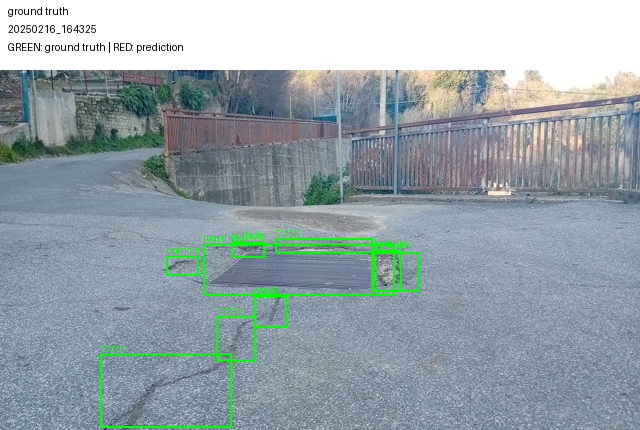

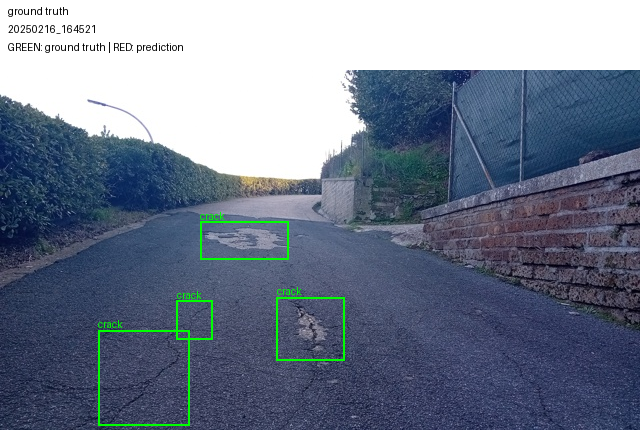

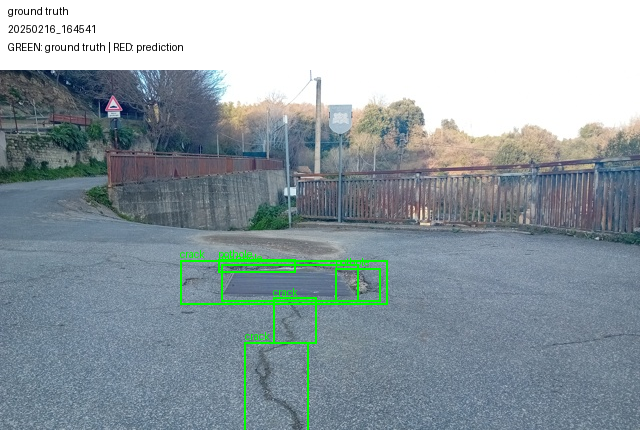

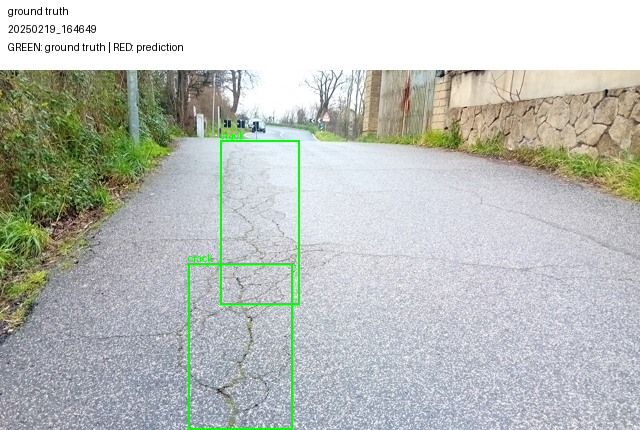

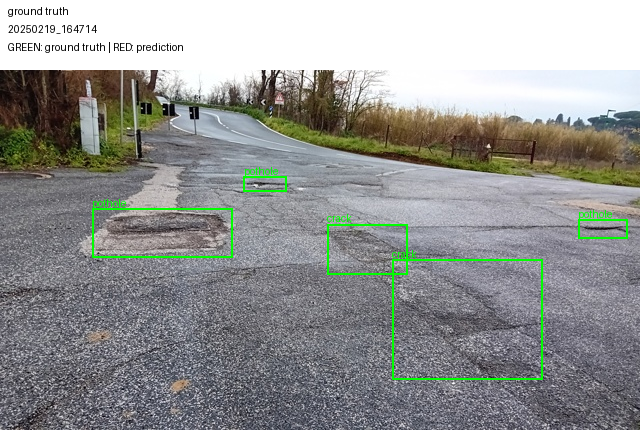

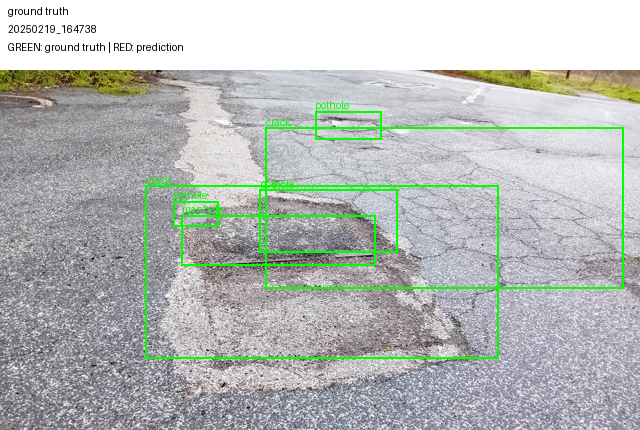

In [7]:
# ---------------- Nhãn YOLO -> JSON 0–1000 ----------------
from IPython.display import display
from PIL import Image
from scripts.labcommon import read_jsonl
from solution.data import objects_to_answer, prompt

train_rows = read_jsonl('data/splits/train.jsonl')
print(prompt())
print(objects_to_answer(train_rows[0]['objects']))
for path in sorted(Path('report/figures/labels').glob('*.png')):
    display(Image.open(path))

## 3. Kiểm tra trước khi chạy dài
Test CPU, tải model một lần, smoke test processor/mask loss.

In [8]:
# ---------------- Test CPU nhanh (soft: lỗi chỉ cảnh báo) ----------------
run_stream(PY('-m', 'pytest', '-q', '-x', 'tests', 'solution/tests'), soft=True)

$ /usr/bin/python3 -m pytest -q -x tests solution/tests
...........................s............................................ [ 69%]
..........ss...................                                          [100%]
100 passed, 3 skipped in 4.21s
-> exit 0 (0.1 phút)


True

In [9]:
# ---------------- Tải model một lần, rồi chạy offline cho mọi tiến trình ----------------
import yaml
MODEL_ID = yaml.safe_load(Path('configs/e1.yaml').read_text(encoding='utf-8'))['model_id']
PREFETCH_SCRIPT = '''
import sys
from huggingface_hub import snapshot_download
print("cached:", snapshot_download(sys.argv[1], revision="main"))
'''
for attempt in range(1, 5):
    if run_stream(PY('-c', PREFETCH_SCRIPT, MODEL_ID), soft=True):
        os.environ['HF_HUB_OFFLINE'] = '1'      # tránh lỗi 5xx thoáng qua của Hub giữa chừng
        print('Model đã cache; các tiến trình sau chạy HF_HUB_OFFLINE=1')
        break
    print(f'Tải model lỗi, thử lại ({attempt}/4)...')
    time.sleep(20 * attempt)
else:
    print('CẢNH BÁO: không prefetch được; các lane sẽ tự tải model (cần Internet).')

# Smoke test CPU: processor + chat template + mask loss + 220 image tokens trên một mẫu thật.
SMOKE = '''
from pathlib import Path
import yaml
from transformers import AutoProcessor
from scripts.labcommon import read_jsonl
from solution.encoding import encode_example
cfg = yaml.safe_load(Path("configs/e1.yaml").read_text(encoding="utf-8"))
proc = AutoProcessor.from_pretrained(cfg["model_id"])
proc.tokenizer.padding_side = "left"
proc.image_processor.size = {"shortest_edge": 65536, "longest_edge": 256 * 32 * 32}
row = read_jsonl("data/splits/train.jsonl")[0]
enc = encode_example(proc, row, "data", "norm1000", 2048)
img = proc.tokenizer.convert_tokens_to_ids("<|image_pad|>")
print("smoke OK: tokens", enc["input_ids"].shape[1], "| image", int((enc["input_ids"] == img).sum()),
      "| supervised", int((enc["labels"] != -100).sum()))
'''
if not run_stream(PY('-c', SMOKE), soft=True):
    print('CẢNH BÁO: smoke test processor lỗi — xem log ở trên; các lane có thể lỗi sớm.')

$ /usr/bin/python3 -c 
import sys
from huggingface_hub import snapshot_download
print("cached:", snapshot_download(sys.argv[1], revision="main"))
 Qwen/Qwen3-VL-4B-Instruct
cached: /root/.cache/huggingface/hub/models--Qwen--Qwen3-VL-4B-Instruct/snapshots/ebb281ec70b05090aa6165b016eac8ec08e71b17
-> exit 0 (0.8 phút)
Model đã cache; các tiến trình sau chạy HF_HUB_OFFLINE=1
$ /usr/bin/python3 -c 
from pathlib import Path
import yaml
from transformers import AutoProcessor
from scripts.labcommon import read_jsonl
from solution.encoding import encode_example
cfg = yaml.safe_load(Path("configs/e1.yaml").read_text(encoding="utf-8"))
proc = AutoProcessor.from_pretrained(cfg["m ...
smoke OK: tokens 601 | image 220 | supervised 249
-> exit 0 (0.2 phút)


In [10]:
# ---------------- (Tuỳ chọn) Dùng lại kết quả E0–E3 hoàn chỉnh từ một lần chạy trước ----------------
# Thêm output của phiên bản notebook cũ làm input (Add Input -> Notebooks -> Your Work -> chọn notebook này).
# Chỉ khôi phục thí nghiệm đã xong đủ (train finished + val + test + evidence); phần còn lại chạy lại.
def find_previous_run():
    root = Path('/kaggle/input')
    if not root.exists():
        return None
    for dirpath, dirnames, _ in os.walk(root):
        dirnames[:] = [d for d in dirnames if d not in ('images', 'labels-YOLO')]
        p = Path(dirpath)
        if (p / 'work').is_dir() and (p / 'report' / 'evidence').is_dir():
            return p
        if len(p.relative_to(root).parts) >= 5:
            dirnames[:] = []
    return None


def restore_experiment(src, exp):
    work, evidence = src / 'work', src / 'report' / 'evidence'
    files = [evidence / f'{exp}.json', work / f'{exp}.jsonl', work / f'{exp}.manifest.json']
    if exp != 'e0':
        run_json = work / exp / 'run.json'
        latest = work / exp / 'latest.json'
        if not (run_json.exists() and latest.exists()):
            return False
        if not json.loads(run_json.read_text(encoding='utf-8')).get('finished'):
            return False
        if not (work / exp / json.loads(latest.read_text(encoding='utf-8'))['checkpoint']).is_dir():
            return False
        files += [work / f'{exp}_val.jsonl', work / f'{exp}_val.manifest.json', work / f'{exp}_val_score.json']
    if not all(f.is_file() for f in files):
        return False
    for f in files:
        dst = Path(f.relative_to(src))
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(f, dst)
    if exp != 'e0':
        shutil.copytree(work / exp, Path('work') / exp, dirs_exist_ok=True)
    return True


previous = find_previous_run()
restored = []
if previous is None:
    print('Không có output chạy trước trong /kaggle/input -> chạy đầy đủ từ đầu.')
else:
    meta_prev = None
    for cand in (previous / 'data' / 'splits' / 'meta.json',):
        if cand.exists():
            meta_prev = json.loads(cand.read_text(encoding='utf-8')).get('dataset_version')
    if meta_prev not in (None, meta['dataset_version']):
        print('Output cũ khác dataset_version -> bỏ qua khôi phục:', meta_prev)
    else:
        for exp in ('e0', 'e1', 'e2', 'e3'):
            if restore_experiment(previous, exp):
                restored.append(exp)
        print('Nguồn:', previous, '| đã khôi phục:', restored or 'không có gì')

Nguồn: /kaggle/input/notebooks/ngan1234/lablzzz/day10 | đã khôi phục: ['e0', 'e1', 'e2']


## 4. E0 zero-shot + E1/E2/E3 SFT (hai GPU song song)
Lane GPU 0: E1 → E3. Lane GPU 1: E0 → E2. Mỗi thí nghiệm: train → val (chọn E4) → test (evidence). Train 300 bước, effective batch 8, giữ nguyên `configs/e1–e3.yaml`.

In [11]:
# ---------------- E0 + E1/E2/E3: train, suy luận val (để chọn E4) rồi test ----------------
e0 = ('E0', [predict_step('E0', 'test', 'work/e0.jsonl', 'report/evidence/e0.json', config='configs/e0.yaml')])
lanes = make_lanes([[sft_group('e1'), sft_group('e3')],     # GPU 0: E1 -> E3
                    [e0, sft_group('e2')]])                 # GPU 1: E0 -> E2
print('Lane:', [(l.lane, l.gpu, [t for t, _ in l.groups]) for l in lanes])
failed_phase1 = run_lanes(lanes)

Lane: [('gpu0', 0, ['E1', 'E3']), ('gpu1', 1, ['E0', 'E2'])]
[gpu0] ===== E1 =====
[gpu0] $ /usr/bin/python3 -m solution.run predict --allow-gpu --checkpoint work/e1 --pred work/e1_val.jsonl --split val --batch-size 8 --resume --score-out work/e1_val_score.json --name E1
[gpu0] All predictions already present; model load skipped
[gpu0] E1 [val] n=276 valid=0.957 P=0.214 R=0.185 F1=0.198 CI95=0.163-0.232 meanIoU=0.688 FP/img=1.57
[gpu0]    pothole  P=0.089 R=0.106 F1=0.097
[gpu0]    crack    P=0.156 R=0.136 F1=0.146
[gpu0]    manhole  P=0.734 R=0.456 F1=0.563
[gpu0] $ /usr/bin/python3 -m solution.run predict --allow-gpu --checkpoint work/e1 --pred work/e1.jsonl --split test --batch-size 8 --resume --score-out report/evidence/e1.json --name E1
[gpu0] All predictions already present; model load skipped
[gpu0] E1 [test] n=311 valid=0.994 P=0.259 R=0.274 F1=0.267 CI95=0.233-0.302 meanIoU=0.676 FP/img=1.47
[gpu0]    pothole  P=0.206 R=0.165 F1=0.183
[gpu0]    crack    P=0.161 R=0.224 F1=0.18

## 5. E4: ablation lượng dữ liệu (10% so với 100%)
Chọn baseline theo F1 val; nhánh 100% dùng lại dự đoán của baseline. E5 (GRPO bonus) chỉ chạy khi `RUN_E5 = True` ở cell đầu.

In [12]:
# ---------------- E4: giảm dữ liệu còn 10% (baseline chọn bằng val) ----------------
failed_phase2 = []
selection = None
if all(Path(f'work/e{n}_val_score.json').exists() for n in (1, 2, 3)):
    if run_stream(PY('-m', 'solution.run', 'select-e4'), soft=True):
        selection = json.loads(Path('work/configs/selection.json').read_text())
else:
    print('Thiếu val score của E1–E3 (lane lỗi?) -> bỏ qua E4. Xem work/logs/*.log')

if selection:
    print(f"Baseline: {selection['base']} (val F1={selection['validation_f1']:.4f})")
    # Nhánh 100% dùng lại dự đoán test của baseline (cùng seed/hyperparameter), chấm lại với run.json baseline.
    base_pred = Path(f"work/{selection['base']}.jsonl")
    if base_pred.exists():
        shutil.copy2(base_pred, 'work/e4_data_100.jsonl')
        run_stream(PY('-m', 'solution.run', 'score', '--pred', 'work/e4_data_100.jsonl',
                      '--checkpoint', selection['checkpoint'], '--name', 'E4_data_100',
                      '--out', 'report/evidence/e4_data_100.json'), soft=True)
    else:
        print('Thiếu dự đoán test của baseline:', base_pred)
    train = train_step('work/configs/e4_data_010.yaml', 'work/e4_data_010')
    e4_steps = ([train] if train else []) + [
        lambda: prune_checkpoints('work/e4_data_010'),
        predict_step('E4_data_010', 'test', 'work/e4_data_010.jsonl', 'report/evidence/e4_data_010.json',
                     checkpoint='work/e4_data_010')]
    groups = [[('E4_data_010', e4_steps)]]
    if RUN_E5:
        e5_steps = [PY('-m', 'solution.run', 'grpo', '--allow-gpu', '--checkpoint', selection['checkpoint'], '--out', 'work/e5'),
                    predict_step('E5', 'test', 'work/e5.jsonl', 'report/evidence/e5.json', checkpoint='work/e5')]
        groups.append([('E5', e5_steps)])
    failed_phase2 = run_lanes(make_lanes(groups))

$ /usr/bin/python3 -m solution.run select-e4
{
  "base": "e3",
  "checkpoint": "work/e3/checkpoint-0300",
  "validation_f1": 0.33777038269550747,
  "dataset_version": "d10-21e4070301",
  "configs": [
    "work/configs/e4_data_010.yaml",
    "work/configs/e4_data_100.yaml"
  ],
  "selection_split": "val"
}
-> exit 0 (0.0 phút)
Baseline: e3 (val F1=0.3378)
$ /usr/bin/python3 -m solution.run score --pred work/e4_data_100.jsonl --checkpoint work/e3/checkpoint-0300 --name E4_data_100 --out report/evidence/e4_data_100.json
E4_data_100 [test] n=311 valid=0.997 P=0.458 R=0.439 F1=0.448 CI95=0.409-0.488 meanIoU=0.697 FP/img=0.97
   pothole  P=0.295 R=0.298 F1=0.296
   crack    P=0.378 R=0.388 F1=0.383
   manhole  P=0.800 R=0.638 F1=0.710
-> exit 0 (0.0 phút)
[gpu0] ===== E4_data_010 =====
[gpu0] $ /usr/bin/python3 -m solution.run train --allow-gpu --config work/configs/e4_data_010.yaml --out work/e4_data_010 --batch-size 2 --grad-accum 4
[gpu0] {"train_images": 142, "trainable_params": 14842675

## 6. Phân tích, báo cáo và tải kết quả
Chỉ sinh báo cáo khi đủ evidence thật; không tạo số liệu thay thế.

In [13]:
# ---------------- Phân tích, báo cáo, đóng gói, dọn dẹp ----------------
keys = ['e0', 'e1', 'e2', 'e3', 'e4_data_010', 'e4_data_100']
missing = [k for k in keys if not Path(f'report/evidence/{k}.json').exists()]
if missing:
    print('THIẾU evidence:', missing, '-> không tạo bảng/báo cáo thay thế. Xem work/logs/*.log')
else:
    run_stream(PY('-m', 'solution.analysis'), soft=True)
    run_stream(PY('-m', 'solution.report', '--write'), soft=True)
    run_stream(PY('scripts/check_submission.py'), soft=True)   # còn FAIL "git commits" là bình thường trên Kaggle

# Bảng tổng kết từ evidence thật.
print(f"\n{'run':<14}{'F1':>8}{'P':>8}{'R':>8}{'valid':>8}{'FP/img':>8}{'train_min':>11}{'VRAM_GB':>9}")
for path in sorted(Path('report/evidence').glob('e*.json')):
    r = json.loads(path.read_text(encoding='utf-8'))
    m, meta = r['micro'], r.get('meta', {})
    print(f"{path.stem:<14}{m['f1']:>8.4f}{m['precision']:>8.4f}{m['recall']:>8.4f}{r['parse_valid_rate']:>8.3f}"
          f"{r['fp_per_image']:>8.2f}{meta.get('train_minutes', 0):>11.1f}{meta.get('peak_vram_gb', 0):>9.2f}")

if Path('REPORT.md').exists():
    print('\n' + Path('REPORT.md').read_text(encoding='utf-8'))

# Gói kết quả (không có trọng số) rồi dọn file nặng để Save Version nhanh.
run_stream(PY('-m', 'solution.package', 'results', '--out', '/kaggle/working/day10_results.zip' if IN_KAGGLE else 'day10_results.zip'), soft=True)
for state in Path('work').glob('*/checkpoint-*/training_state.pt'):
    state.unlink()
if not KEEP_ADAPTERS:
    for ckpt in Path('work').glob('*/checkpoint-*'):
        shutil.rmtree(ckpt, ignore_errors=True)
if CLEAN_DATA_IMAGES:
    shutil.rmtree('data/images', ignore_errors=True)
    shutil.rmtree('work/raw', ignore_errors=True)
size = sum(f.stat().st_size for f in REPO_DIR.rglob('*') if f.is_file()) / 1e9
print(f'\nHoàn tất sau {(time.time() - T_START) / 3600:.2f} giờ. Kích thước {REPO_DIR}: {size:.2f} GB')
print('Tải về: day10_results.zip, report/evidence/*.json, REPORT.md, report/figures/, work/*.jsonl')
print('Thí nghiệm lỗi:', globals().get('failed_phase1', []) + globals().get('failed_phase2', []) or 'không có')

$ /usr/bin/python3 -m solution.analysis
{
  "dataset_version": "d10-21e4070301",
  "audit": {
    "dataset_version": "d10-21e4070301",
    "session_overlap": false,
    "splits": {
      "train": {
        "images": 1422,
        "boxes": {
          "pothole": 1074,
          "crack": 1750,
          "manhole": 691
        },
        "sessions": 13,
        "median_box_area": {
          "pothole": 0.0037586894095,
          "crack": 0.013465637066,
          "manhole": 0.00390625
        },
        "unusable_target_boxes": {
          "pothole": 0,
          "crack": 1,
          "manhole": 0
        },
        "unusable_target_examples": [
          {
            "image_id": "vlcsnap-00058",
            "object_index": 1,
            "label": "crack",
            "yolo": [
              0.639062,
              0.786111,
              0.003125,
              0.0
            ],
            "reason": "zero_area"
          }
        ]
      },
      "val": {
        "images": 276,
     